<table border=0 width="100%"><tr><td><p align="left"><font size=5><B>数据分析与可视化</B></font></p></td><td><font size=3><B>Exploratory Data Analysis(郑海超)</B></font></td></tr></table>

# 应用EDA分析节日效应

- 大家后续可以研究阅读效应

新闻：十大券商看后市｜A股节后有望迎修复行情，建议均衡配置

https://news.qq.com/rain/a/20261008A039YI00

### 下载上证指数日线

先下载再分析。上证指数代码 `000001.SH`，从 2001 年取到 2026 年 10 月 10 日。接口单次有行数上限，按年取再拼起来，并落盘。

In [3]:
import tushare as ts
import pandas as pd

In [4]:
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token)
pro = ts.pro_api()

frames = []
for year in range(2001, 2027):
    end = "20261010" if year == 2026 else f"{year}1231"
    part = pro.index_daily(ts_code="000001.SH", start_date=f"{year}0101", end_date=end)
    frames.append(part)

raw = pd.concat(frames, ignore_index=True)
raw["trade_date"] = pd.to_datetime(raw["trade_date"].astype(str))
raw = raw.sort_values("trade_date")
raw.to_csv("sh_index_daily.csv", index=False)
raw["trade_date"].min(), raw["trade_date"].max(), raw.shape

(Timestamp('2001-01-02 00:00:00'),
 Timestamp('2026-10-09 00:00:00'),
 (6245, 11))

### 读入收盘价

这一格只留下日期和收盘价。问：这格得到了什么？

In [5]:
# 读取数据 read_csv函数 - read_csv("sh_index_daily.csv")
df = pd.read_csv("sh_index_daily.csv")
df.head()

,ts_code,trade_date,close,open,high,low,pre_close,change,pct_chg,vol,amount
0,000001.SH,2001-01-02,2103.469,2077.076,2103.538,2074.882,2073.477,29.992,1.4465,18650746.0,1.340509e+07
1,000001.SH,2001-01-03,2123.899,2108.254,2123.900,2105.497,2103.469,20.430,0.9713,17157673.0,1.751683e+07
2,000001.SH,2001-01-04,2117.405,2125.485,2127.419,2113.179,2123.899,-6.494,-0.3058,13423541.0,1.429525e+07
3,000001.SH,2001-01-05,2125.300,2117.664,2125.381,2114.056,2117.405,7.895,0.3729,13288175.0,1.484424e+07
4,000001.SH,2001-01-08,2102.064,2128.602,2131.980,2092.097,2125.300,-23.236,-1.0933,14787085.0,1.588766e+07


In [9]:
# 这里是对df数据按列做切片 - df[["trade_date", "close"]].copy()
close = df[["trade_date","close"]].copy()
# 查看几行数据，最后几行 或者前几行
close.head(10)

,trade_date,close
0,2001-01-02,2103.469
1,2001-01-03,2123.899
2,2001-01-04,2117.405
3,2001-01-05,2125.300
4,2001-01-08,2102.064
5,2001-01-09,2101.135
6,2001-01-10,2125.615
7,2001-01-11,2119.141
8,2001-01-12,2104.747
9,2001-01-15,2032.443


### 日期转为 datetime，设为索引并排序

`trade_date` 现在多半是 `20011231` 这样的数字或字符串。转成日期、放到索引上，再按时间从早到晚排。不排序的话，下一格的收益率会用错相邻两天。

In [11]:
# 将字符串转换为日期格式 pd.to_datetime(close["trade_date"].astype(str))
# 设置索引 set_index("trade_date")
# 按索引排序 sort_index()
close["trade_date"] = pd.to_datetime(close["trade_date"].astype(str))
close = close.set_index("trade_date")
close.head()

,close
trade_date,
2001-01-02,2103.469
2001-01-03,2123.899
2001-01-04,2117.405
2001-01-05,2125.300
2001-01-08,2102.064


# 补充：泰勒公式与麦克劳林公式

泰勒公式的核心思想是：利用函数在某一点的函数值及各阶导数，把这个函数在该点附近近似成多项式。展开点取 $a=0$ 时，称为麦克劳林公式：

$$f(x)=f(0)+f'(0)x+\frac{f''(0)}{2!}x^2+\frac{f'''(0)}{3!}x^3+\cdots+\frac{f^{(n)}(0)}{n!}x^n+\cdots$$


### 简单收益率和对数收益率

- 简单收益率 $R=P_t/P_{t-1}-1$，用 `pct_change`。
- 对数收益率 $r=\ln(P_t/P_{t-1})=\ln(1+R)$。

把 $f(R)=\ln(1+R)$ 在 $R=0$ 处做泰勒展开。$f(0)=0$，$f'(R)=1/(1+R)$ 所以 $f'(0)=1$，$f''(R)=-1/(1+R)^2$ 所以 $f''(0)=-1$。于是

$$\ln(1+R)=R-\frac{R^2}{2}+\frac{R^3}{3}-\frac{R^4}{4}+\cdots$$

日涨跌 $R=0.01$（涨 1%）时，第二项只有 $0.00005$，所以 $\ln(1.01)\approx 0.00995$，和 $0.01$ 几乎一样。$R=0.08$（涨 8%）时，第二项是 $0.0032$，$\ln(1.08)\approx 0.077$，就和 $R$ 拉开了。本周分组分析会同时考虑简单收益率和对数收益率。

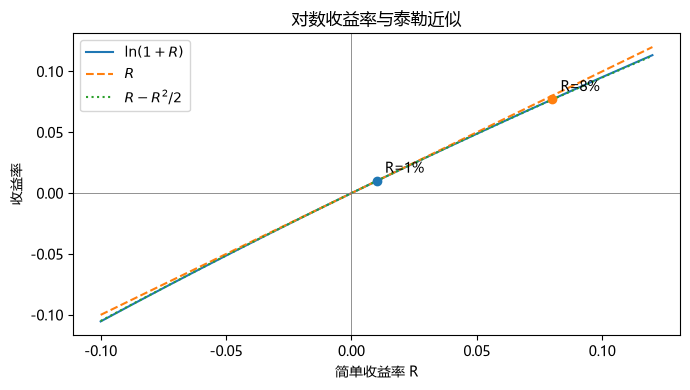

In [12]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

R = np.linspace(-0.10, 0.12, 400)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(R, np.log(1 + R), label=r"$\ln(1+R)$")
ax.plot(R, R, linestyle="--", label=r"$R$")
ax.plot(R, R - R**2 / 2, linestyle=":", label=r"$R-R^2/2$")
for x in (0.01, 0.08):
    ax.scatter([x], [np.log(1 + x)], zorder=3)
    ax.annotate(f"R={x:.0%}", (x, np.log(1 + x)), textcoords="offset points", xytext=(6, 6))
ax.axhline(0, color="gray", linewidth=0.6)
ax.axvline(0, color="gray", linewidth=0.6)
ax.set_xlabel("简单收益率 R")
ax.set_ylabel("收益率")
ax.set_title("对数收益率与泰勒近似")
ax.legend()
plt.tight_layout()

In [13]:
import numpy as np

close["R"] = close["close"].pct_change()

In [14]:
close.head()

,close,R
trade_date,,
2001-01-02,2103.469,NaN
2001-01-03,2123.899,0.009713
2001-01-04,2117.405,-0.003058
2001-01-05,2125.300,0.003729
2001-01-08,2102.064,-0.010933


In [ ]:
close["close_shift"] = close["close"].shift(1)
close.head()

In [17]:
close.head()

,close,R,close_shift
trade_date,,,
2001-01-02,2103.469,NaN,NaN
2001-01-03,2123.899,0.009713,2103.469
2001-01-04,2117.405,-0.003058,2123.899
2001-01-05,2125.300,0.003729,2117.405
2001-01-08,2102.064,-0.010933,2125.300


In [18]:
# 计算对数收益率 - np.log(close["close"] / close["close"].shift(1))
close["log_return"] = np.log(close["close"]/close["close_shift"])
close.head()

,close,R,close_shift,log_return
trade_date,,,,
2001-01-02,2103.469,NaN,NaN,NaN
2001-01-03,2123.899,0.009713,2103.469,0.009666
2001-01-04,2117.405,-0.003058,2123.899,-0.003062
2001-01-05,2125.300,0.003729,2117.405,0.003722
2001-01-08,2102.064,-0.010933,2125.300,-0.010993


In [19]:
# loc 按标签取数。这一行里逗号前后是两套标签：前面选哪几行，后面选哪几列
close.loc[["2001-06-13", "2024-09-24"], ["close", "R", "log_return"]]

,close,R,log_return
trade_date,,,
2001-06-13,2242.4230,0.008756,0.008718
2024-09-24,2863.1255,0.041546,0.040707


In [20]:
# 获取所有行 - loc[:,["close", "R", "log_return"]]
close.loc[:,["close", "R", "log_return"]]

,close,R,log_return
trade_date,,,
2001-01-02,2103.4690,NaN,NaN
2001-01-03,2123.8990,0.009713,0.009666
2001-01-04,2117.4050,-0.003058,-0.003062
2001-01-05,2125.3000,0.003729,0.003722
2001-01-08,2102.0640,-0.010933,-0.010993
...,...,...,...
2026-09-28,3823.6206,-0.016653,-0.016793
2026-09-29,3830.4513,0.001786,0.001785
2026-09-30,3842.1946,0.003066,0.003061


### 给每个交易日打窗口标签

新加一列 `窗口`。每年 10 月 1 日之前的 5 个交易日写成「节前」，之后的 5 个交易日写成「节后」，其余写成「普通日」。10 月 1 日本身不是交易日，不占一行。

In [21]:
import pandas as pd

def label_window(dates, n=10):
    """给每个交易日打上国庆窗口标签。

    n 是窗口长度，单位是交易日，不是日历日。
    每年 10 月 1 日之前最近的 n 个交易日标为「节前」，
    之后最近的 n 个交易日标为「节后」，其余标为「普通日」。
    """
    dates = pd.DatetimeIndex(pd.to_datetime(dates)).sort_values()
    window = pd.Series("普通日", index=dates, name="窗口")
    for year in range(dates.min().year, dates.max().year + 1):
        oct1 = pd.Timestamp(year=year, month=10, day=1)
        window.loc[dates[dates < oct1][-n:]] = "节前"
        window.loc[dates[dates > oct1][:n]] = "节后"
    return window

# 一小段交易日：休市日没放进来，所以「之后 5 个」就是节后 5 个交易日
demo = pd.to_datetime([
    "2024-09-20", "2024-09-23", "2024-09-24", "2024-09-25", "2024-09-26",
    "2024-09-27", "2024-09-30",
    "2024-10-08", "2024-10-09", "2024-10-10", "2024-10-11", "2024-10-14",
    "2024-10-15",
])
label_window(demo)

2024-09-20    节前
2024-09-23    节前
2024-09-24    节前
2024-09-25    节前
2024-09-26    节前
2024-09-27    节前
2024-09-30    节前
2024-10-08    节后
2024-10-09    节后
2024-10-10    节后
2024-10-11    节后
2024-10-14    节后
2024-10-15    节后
Name: 窗口, dtype: str

In [28]:
n = 3  # 改成 1、3、10，从这一格重新运行到三张图
close = close.loc[close.index.year < 2026].copy()
close["窗口"] = label_window(close.index, n)
close["窗口"].value_counts()

窗口
普通日    5912
节前       75
节后       75
Name: count, dtype: int64

### 按窗口分组

看每组有多少天、简单收益率的平均。只看节前和节后，不拿普通日对比。节前、节后应接近「年份数 × n」。改 `n` 后，天数和平均收益都会变。

In [29]:
# 切片
holiday = close.loc[close["窗口"].isin(["节前", "节后"])]
# 分组并汇总
holiday.groupby("窗口")["R"].agg(["count", "mean"])

,count,mean
窗口,,
节前,75,0.002131
节后,75,0.002732


In [30]:
holiday.groupby("窗口")["log_return"].agg(["count", "mean"])

,count,mean
窗口,,
节前,75,0.002018
节后,75,0.002548


### 涨跌次数比例

平均收益率会被少数大涨大跌拉开。这一节只数天数：上涨天数占该窗口的比例。不放入普通日。平盘（收益为 0）两边都不计。节后第一根收益跨过整段休市，仍只算一次。

**看什么：** 节前和节后，上涨天数是否明显更多。

**发现什么：** `n = 3`、2001–2025 年时，节前上涨约 53%，节后上涨约 63%。节后上涨的天数更多，下跌天数更少。

**因此假设什么：** 节后偏向上涨的日子更多。这和平均收益不是同一件事：次数接近时，平均收益仍可能因幅度不同而分开。改 `n` 后要重跑这一节，比例会变。

In [31]:
rows = []
for name, part in holiday.groupby("窗口"):
    s = part["R"].dropna()
    rows.append({
        "窗口": name,
        "天数": len(s),
        "上涨比例": (s > 0).mean(),
        "下跌比例": (s < 0).mean(),
    })
up_ratio = pd.DataFrame(rows).set_index("窗口")
up_ratio

,天数,上涨比例,下跌比例
窗口,,,
节前,75,0.533333,0.466667
节后,75,0.626667,0.373333


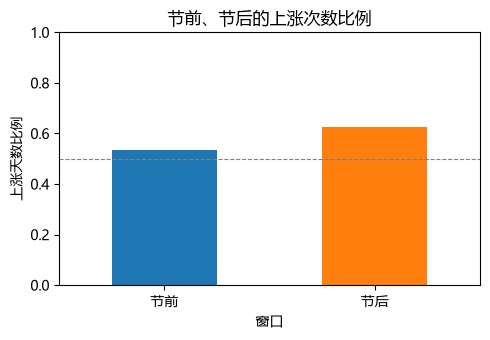

In [32]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

ratio = up_ratio["上涨比例"]
if isinstance(ratio.index, pd.MultiIndex):
    ratio = up_ratio.xs("上涨比例", level=-1)

fig, ax = plt.subplots(figsize=(5, 3.5))
ratio.plot.bar(ax=ax, color=["C0", "C1"], rot=0)
ax.set_ylim(0, 1)
ax.set_ylabel("上涨天数比例")
ax.set_title("节前、节后的上涨次数比例")
ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
plt.tight_layout()

### 视角 1 · 分布

节前和节后的日收益率放在一起比，不放入普通日。直方图用密度。节后第一根日收益跨过整段休市，不是普通的一天。

In [ ]:
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(8, 4))
for name in ["节前", "节后"]:
    close.loc[close["窗口"] == name, "R"].dropna().hist(
        ax=ax, bins=40, density=True, alpha=0.45, label=name
    )
ax.set_xlim(-0.08, 0.08)
ax.set_title("日收益率分布：节前、节后")
ax.set_xlabel("简单收益率 R")
ax.legend()
plt.tight_layout()

### 视角 2 · 趋势

以长假为第 0 天。第 0 天没有成交，线在这里断开，不补收益 0。纵轴是相对节前第 `n` 个交易日收盘价的累计涨跌。分析只用 2001–2025 年，不含 2026 年。

In [ ]:
records = []
for year in range(close.index.min().year, close.index.max().year + 1):
    oct1 = pd.Timestamp(year=year, month=10, day=1)
    pre = close.index[close.index < oct1][-n:]
    post = close.index[(close.index > oct1) & (close.index < oct1 + pd.Timedelta(days=7 + 3 * n))][:n]
    if len(pre) < n:
        continue
    days = list(pre) + list(post)
    ks = list(range(-n, 0)) + list(range(1, len(post) + 1))
    base = close.loc[pre[0], "close"]
    for k, day in zip(ks, days):
        records.append({"year": year, "k": k, "cum": close.loc[day, "close"] / base - 1})

wide = pd.DataFrame(records).pivot(index="year", columns="k", values="cum")
avg = wide.mean()

def plot_gap(ax, row, **kwargs):
    left = row[row.index < 0]
    right = row[row.index > 0].dropna()
    ax.plot(left.index, left.values, **kwargs)
    if len(right):
        ax.plot(right.index, right.values, **kwargs)

fig, ax = plt.subplots(figsize=(8, 4))
for year, row in wide.iterrows():
    plot_gap(ax, row, color="0.8", linewidth=0.8)
plot_gap(ax, avg, color="C0", linewidth=2, label="2001–2025 平均")
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("国庆窗口累计收益（第 0 天休市，线是断开的）")
ax.set_xlabel("相对 10 月 1 日的第几个交易日")
ax.set_ylabel("相对节前第 5 天收盘价的累计涨跌")
ax.legend()
plt.tight_layout()

**看什么：** 各年的线是散开的，还是平均线在节前就明显抬起来。

**发现什么：** 2001–2025 年的平均线在节前接近走平，到休市前一天累计大约只有不到 1 个百分点。从节前最后一天接到节后第一天，中间含有整段休市。

**因此假设什么：** 平均意义上，节前没有稳定的大涨。个别年份会离开这条平均线。

### 视角 3 · 异常

横轴是年份。左图是节前累计收益：从节前第 `n` 天到休市前一天。右图是节后累计收益：从休市前最后一个收盘价到节后第 `n` 天，含整段休市。横线各是 2001–2025 年的平均。

In [ ]:
pre_cum = wide[-1]
post_cum = (wide[n] + 1) / (wide[-1] + 1) - 1

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, series, title in [
    (axes[0], pre_cum, "节前累计收益"),
    (axes[1], post_cum, "节后累计收益"),
]:
    ax.bar(series.index.astype(str), series.values, color="C0")
    ax.axhline(series.mean(), color="black", linewidth=1, label="2001–2025 平均")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    ax.legend(fontsize=8)
axes[0].set_ylabel("累计涨跌")
plt.tight_layout()

**看什么：** 节前、节后各自有哪些年离开平均线，两边是不是同一批年份。

**发现什么：** 节前偏离最大的是 2024 年，那一小段涨得远高于其他年份。节后偏离最大的是 2008 年，节后这一小段明显下跌。2024 年的节前大涨没有延续到节后。

**因此假设什么：** 国庆前的上涨、节后的下跌都不是每年都有，而且不是同一批年份造成的。看到平均差别时，要先看是不是少数年份拉出来的。大约二十五个完整长假只够形成假设，不能写成已经成立的因子。

### 去掉异常年份后再做一遍

视角 3 里，节前偏离最大的是 2024 年，节后偏离最大的是 2008 年。这一节把这两个年份整年拿掉，其余设置不变：仍是 2001–2025 里剩下的年份，窗口长度仍用上面的 `n`，只比较节前和节后。下面按同一套步骤重做：平均收益、涨跌天数比例、分布、走势、分年累计。

按当前 `n = 7`：去掉这两年以前，节前累计的多年平均约为 +1.1%，节后约为 +0.5%。拿掉之后，节前累计平均约为 -0.7%，节后约为 +1.2%。日收益率的平均也一样：节前由略正变成略负，节后仍为正。上涨天数比例仍然是节后高于节前。

**因此假设什么：** 全样本里看到的节前上涨，主要是 2024 年拉出来的。节后略偏向上涨，拿掉 2008 年的大跌之后还在。改 `n` 后从这一节重新运行，数字会变。


In [ ]:
drop_years = [2008, 2024]
sample = close.loc[~close.index.year.isin(drop_years)].copy()
sub = sample.loc[sample["窗口"].isin(["节前", "节后"])]
display(sub.groupby("窗口")["R"].agg(["count", "mean"]))
display(sub.groupby("窗口")["log_return"].agg(["count", "mean"]))


In [ ]:
rows = []
for name, part in sub.groupby("窗口"):
    s = part["R"].dropna()
    rows.append({"窗口": name, "天数": len(s), "上涨比例": (s > 0).mean(), "下跌比例": (s < 0).mean()})
pd.DataFrame(rows).set_index("窗口")


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for name in ["节前", "节后"]:
    sub.loc[sub["窗口"] == name, "R"].dropna().hist(
        ax=ax, bins=40, density=True, alpha=0.45, label=name
    )
ax.set_xlim(-0.08, 0.08)
ax.set_title("去掉 2008、2024 后的日收益率分布")
ax.set_xlabel("简单收益率 R")
ax.legend()
plt.tight_layout()


In [ ]:
records = []
for year in range(sample.index.min().year, sample.index.max().year + 1):
    if year in drop_years:
        continue
    oct1 = pd.Timestamp(year=year, month=10, day=1)
    pre = sample.index[sample.index < oct1][-n:]
    post = sample.index[(sample.index > oct1) & (sample.index < oct1 + pd.Timedelta(days=7 + 3 * n))][:n]
    if len(pre) < n or len(post) < n or pre[-1].year != year or post[0].year != year:
        continue
    days = list(pre) + list(post)
    ks = list(range(-n, 0)) + list(range(1, len(post) + 1))
    p0 = sample.loc[pre[0], "close"]
    for k, day in zip(ks, days):
        records.append({"year": year, "k": k, "cum": sample.loc[day, "close"] / p0 - 1})

wide2 = pd.DataFrame(records).pivot(index="year", columns="k", values="cum")
avg2 = wide2.mean()
pre_cum2 = wide2[-1]
post_cum2 = (wide2[n] + 1) / (wide2[-1] + 1) - 1

fig, ax = plt.subplots(figsize=(8, 4))
for year, row in wide2.iterrows():
    plot_gap(ax, row, color="0.8", linewidth=0.8)
plot_gap(ax, avg2, color="C0", linewidth=2, label="去掉异常年后的平均")
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("去掉 2008、2024 后的国庆窗口累计收益")
ax.set_xlabel("相对 10 月 1 日的第几个交易日")
ax.set_ylabel("相对节前第 n 天收盘价的累计涨跌")
ax.legend()
plt.tight_layout()


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, series, title in [
    (axes[0], pre_cum2, "节前累计收益"),
    (axes[1], post_cum2, "节后累计收益"),
]:
    ax.bar(series.index.astype(str), series.values, color="C0")
    ax.axhline(series.mean(), color="black", linewidth=1, label="去掉异常年后的平均")
    ax.set_title(title)
    ax.tick_params(axis="x", labelrotation=90, labelsize=7)
    ax.legend(fontsize=8)
axes[0].set_ylabel("累计涨跌")
plt.tight_layout()


### 结果总结与分析

按当前 `n = 7`、2001–2025 年，节前和节后的差别可以收成三句话。

日收益率的分布叠在一起，典型的一天没有分开。分开的是幅度：节后第一天从休市前的收盘接到节后开市，中间是整段国庆，所以这一天更容易出现较大的涨跌。上涨天数节后略多，全样本大约 46% 对 53%；去掉 2008 和 2024 之后大约 43% 对 54%。天数和平均收益是两件事。累计收益上，全样本节前约 +1.1%、节后约 +0.5%；拿掉这两年之后，节前约 -0.7%、节后约 +1.2%。节前那段正的平均，主要是 2024 年贡献的。

节前和节后会不一样，对应两件能在数据里指出来的事。

第一，两边的收益不是同一种「一天」。节前窗口里每个交易日都紧挨着上一个交易日。节后第一天的简单收益跨过整个休市：海外市场在这几天里还在交易，国内的消息也会堆到开市后一起反映。分布图里节后的尾巴更长，首先来自这个日历。

第二，窗口会把假期旁边发生的冲击一起算进去。2024 年 9 月 24 日前后，央行等部门推出一揽子增量政策，上证在休市前连续大涨，节前这 `n` 天正好盖住这段行情，所以这一年把节前平均抬得很高，开市后并没有按同样幅度继续。2008 年 9 月中旬雷曼兄弟倒闭，全球市场在国庆前后继续下跌，节后这 `n` 天盖住的是这场危机，所以这一年把节后平均拉低。视角 3 里最显眼的两根柱子，就是这两个年份，而且它们分别出现在节前和节后。

拿掉这两年之后，剩下的差别只有大约一个百分点：节前累计略负，节后累计略正，节后上涨的天数仍然多一些。节前略负，和长假前减少持仓、避开几天无法交易的方向一致。节后略正、波动更大，和假期里积累的信息在开市后集中反映的方向一致。样本只有二十多个完整长假，改 `n` 之后数字会变，所以这两句话先写成假设。写结论时要同时写上窗口长度、用的是简单收益率，以及拿掉 2008、2024 之后平均有没有换方向。
